> Since 2026-10-23 the `eda/` scripts named below are the pipeline `src/vcell` (`python -m vcell qc controls`, `etl download`, `etl coverage`) and `experiments/` (index `experiments/README.md`); results are in `out/`. The cells read the cached results there.

# EDA: Virtual Cell 2026 (validation panel)

Run order: the four scripts in `eda/` write their results to `eda/out/`; this notebook reads them and lets you
explore further. Start at section 1 (needs only `01_context_summary.py`), then 2 to 4 as the data arrive.
Plan and decision rules: `docs/archive/EDA_PLAN.md`. Each section ends with **Questions to try** you can answer by editing the cells.

```
py -3.9 eda/01_context_summary.py        # 20 s, no download
py -3.9 eda/02_download_small.py         # 0.7 GB
py -3.9 eda/03_coverage.py               # 10 s
py -3.9 eda/04_concordance_k562_cd4.py   # 8 min, reads 0.15 GB remotely
```

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vcell import config as C, io   # was eda/common.py
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "figure.figsize": (6, 3.5)})
man, panel, genes = C.manifest(), C.panel_targets(), C.gene_names()
gidx = {g: i for i, g in enumerate(genes)}
CTX = man["contexts"]
colors = dict(zip(CTX, ["#1b6ca8", "#d1495b", "#2a9d8f"]))
print("contexts", CTX, "| panel", len(panel), "| genes", len(genes))

contexts ['A', 'B', 'C'] | panel 300 | genes 18533


## 1. The organisers' control cells (contexts A, B, C)
Question: what do we know about the three lines from the controls alone?

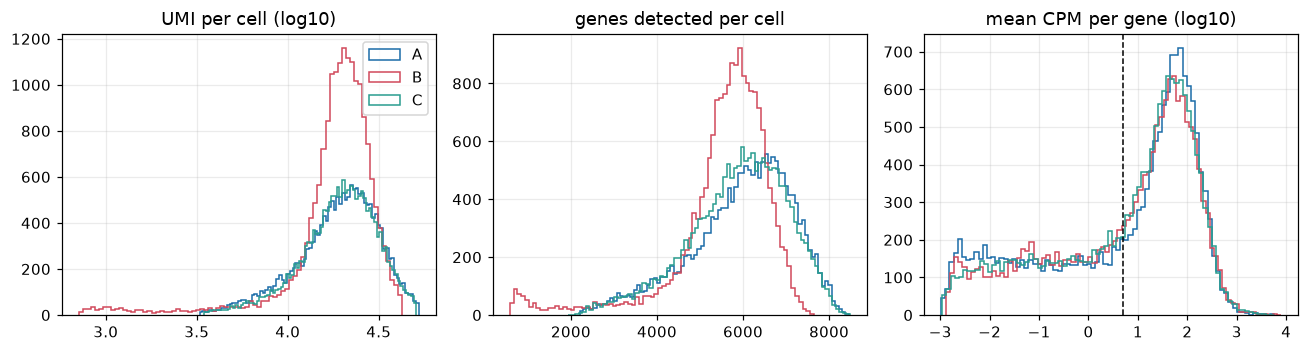

                         A        B        C
genes > 5 CPM       9929.0   9626.0  10124.0
median UMI         20109.0  19946.0  20034.0
median genes/cell   6147.0   5756.0   6006.0


In [2]:
S = np.load(C.OUT / "context_summary.npz", allow_pickle=True)
mean_cpm = {c: S[f"{c}_mean_cpm"] for c in CTX}
detect = {c: S[f"{c}_detect"] for c in CTX}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for c in CTX:
    ax[0].hist(np.log10(S[f"{c}_tot"]), 80, histtype="step", color=colors[c], label=c)
    ax[1].hist(S[f"{c}_ngenes"], 80, histtype="step", color=colors[c], label=c)
    m = mean_cpm[c] > 0
    ax[2].hist(np.log10(mean_cpm[c][m]), 80, histtype="step", color=colors[c], label=c)
ax[0].set(title="UMI per cell (log10)"); ax[1].set(title="genes detected per cell"); ax[2].set(title="mean CPM per gene (log10)")
ax[2].axvline(np.log10(C.CPM_FILTER), color="k", ls="--", lw=1)
ax[0].legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({c: {"genes > 5 CPM": int((mean_cpm[c] > 5).sum()),
                        "median UMI": float(np.median(S[f'{c}_tot'])),
                        "median genes/cell": float(np.median(S[f'{c}_ngenes']))} for c in CTX}))

**Read:** depth is the same in all three (about 20,000 UMI), B has fewer genes per cell. The testable gene set is
about 10,000 per context and 7,991 shared. `docs/SCORING.md` only tests genes above the dashed line.

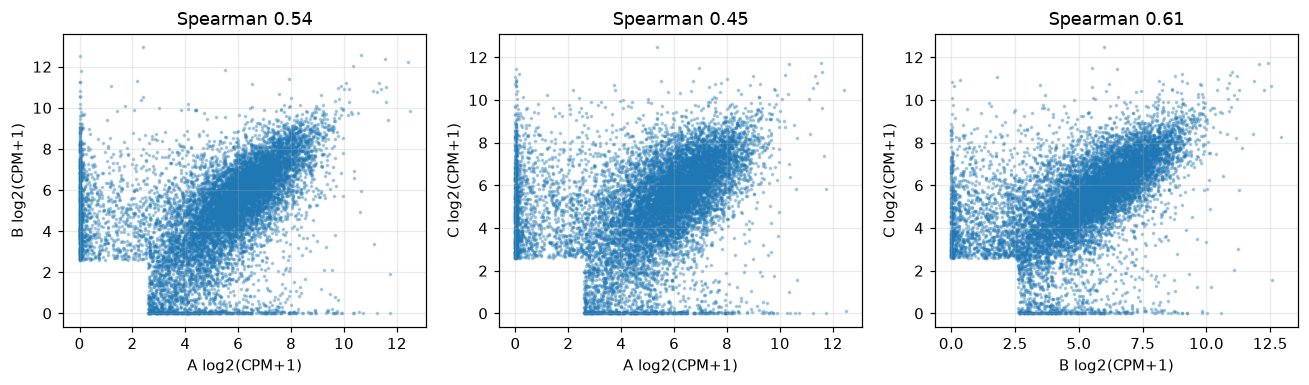

In [3]:
# How different are the contexts? Scatter of log2(CPM+1) between two contexts, genes above 5 CPM in either.
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a, (x, y) in zip(ax, [("A", "B"), ("A", "C"), ("B", "C")]):
    keep = (mean_cpm[x] > 5) | (mean_cpm[y] > 5)
    a.scatter(np.log2(mean_cpm[x][keep] + 1), np.log2(mean_cpm[y][keep] + 1), s=2, alpha=.3)
    r = pd.Series(np.log2(mean_cpm[x][keep] + 1)).corr(pd.Series(np.log2(mean_cpm[y][keep] + 1)), method="spearman")
    a.set(xlabel=f"{x} log2(CPM+1)", ylabel=f"{y} log2(CPM+1)", title=f"Spearman {r:.2f}")
plt.tight_layout(); plt.show()

In [4]:
# Marker genes: which kind of cell is each context? (inference from controls only)
markers = {"T cell": ["CD3D", "CD3E", "LCK", "CD2"], "epithelial": ["EPCAM", "KRT8", "KRT18", "KRT5", "CDH1"],
           "mesenchymal": ["VIM", "FN1", "COL1A1"], "pluripotent": ["SOX2", "POU5F1", "LIN28A"],
           "erythroid": ["TAL1", "GATA1", "HBE1"], "Y chromosome": ["DDX3Y", "RPS4Y1", "UTY"]}
rows = [(grp, g, *[mean_cpm[c][gidx[g]] for c in CTX]) for grp, gs in markers.items() for g in gs if g in gidx]
pd.DataFrame(rows, columns=["group", "gene", *CTX]).round(1)

,group,gene,A,B,C
0,T cell,CD3D,939.299988,0.000000,0.000000
1,T cell,CD3E,760.400024,0.000000,0.000000
2,T cell,LCK,430.500000,0.000000,0.000000
3,T cell,CD2,256.399994,0.000000,0.000000
4,epithelial,EPCAM,0.000000,2.300000,309.500000
5,epithelial,KRT8,3.500000,2505.699951,1427.199951
6,epithelial,KRT18,0.100000,835.400024,666.900024
7,epithelial,KRT5,0.000000,0.000000,1812.199951
8,epithelial,CDH1,0.000000,0.000000,126.900002
9,mesenchymal,VIM,1612.400024,6051.899902,2.000000


**Questions to try**
- Add your own marker genes (HEK293 vs HCT116 vs A549 lists, neuronal genes) and see which contexts match.
- Which genes are high in A but absent in B and C? Is the list enriched for T-cell or cell-cycle genes?
- Compare the three contexts' detection rate (`detect`) against mean CPM: is B really sparser at the same expression?

### 1b. The panel targets in the controls
A knocked-down gene that is barely expressed at baseline cannot show a visible knockdown.

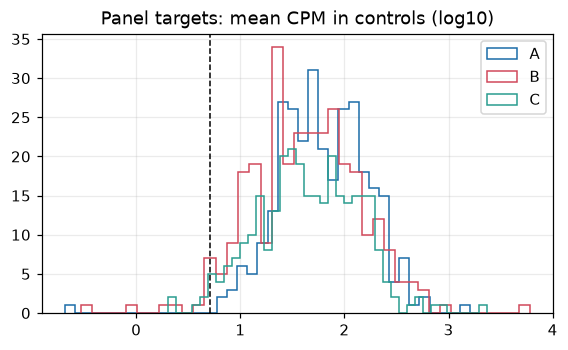

targets at or below 5 CPM: {'A': ['S100A11'], 'B': ['KIF21B', 'PHF11', 'PSMB9', 'ZKSCAN3', 'ZNF25'], 'C': ['DRG2', 'KIF21B', 'RBM4B', 'VIM', 'ZNF324', 'ZNF628', 'ZNF784']}


,A,B,C
count,300.0,300.0,300.0
mean,98.6,100.1,84.7
std,127.0,361.4,164.2
min,0.1,0.2,1.9
25%,31.8,20.3,21.5
50%,59.1,43.9,44.2
75%,118.4,93.0,103.6
max,1612.4,6051.9,2353.9


In [5]:
t_idx = np.array([gidx[t] for t in panel])
tab = pd.DataFrame({c: mean_cpm[c][t_idx] for c in CTX}, index=panel)
fig, ax = plt.subplots(figsize=(6, 3.3))
for c in CTX:
    ax.hist(np.log10(tab[c] + 0.1), 40, histtype="step", color=colors[c], label=c)
ax.axvline(np.log10(5.1), color="k", ls="--", lw=1); ax.set(title="Panel targets: mean CPM in controls (log10)"); ax.legend(); plt.show()
print("targets at or below 5 CPM:", {c: list(tab.index[tab[c] <= 5]) for c in CTX})
tab.describe().round(1)

### 1c. Null calibration with the 46 non-targeting guides
Each `ntc_id` (400 cells) is a fake perturbation against the other 45 guides. z should be N(0,1) if `s` is right.

context  cpm_bin  genes  median_se  sd_z  share_abs_z_gt_1.96  zero_in_group_share
      A     5-10    778      0.225 1.031                0.057                  0.0
      A    10-50   3689      0.119 1.032                0.057                  0.0
      A   50-200   4308      0.066 1.050                0.059                  0.0
      A 200-1000   1120      0.041 1.094                0.068                  0.0
      A 1000-inf     34      0.030 1.199                0.082                  0.0
      B     5-10    936      0.226 1.050                0.060                  0.0
      B    10-50   3864      0.131 1.042                0.059                  0.0
      B   50-200   3651      0.072 1.025                0.056                  0.0
      B 200-1000   1124      0.043 1.032                0.056                  0.0
      B 1000-inf     51      0.029 1.079                0.074                  0.0
      C     5-10    995      0.216 1.021                0.054                  0.0
    

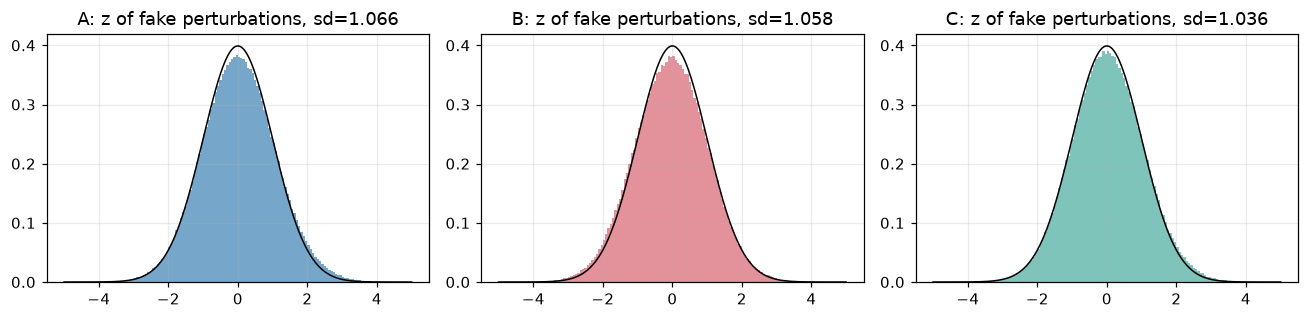

In [6]:
nt = pd.read_csv(C.OUT / "null_calibration.csv")
print(nt.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
x = np.linspace(-5, 5, 400)
for a, c in zip(ax, CTX):
    z = S[f"{c}_null_z"].ravel(); z = z[np.isfinite(z)]
    a.hist(z, 150, range=(-5, 5), density=True, alpha=.6, color=colors[c]); a.plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k", lw=1)
    a.set(title=f"{c}: z of fake perturbations, sd={z.std():.3f}")
plt.tight_layout(); plt.show()

**Read:** sd(z) is 1.0 to 1.1, so the delta-method `s` is close to calibrated; the only visible inflation is at very
high expression (above 1000 CPM, 34 to 56 genes). Real source datasets will differ (guide, batch and donor effects).

**Questions to try**
- Do particular `ntc_id` groups have more |z| > 3 than others (batch structure)? `S[f"{c}_ntc_codes"]`, `S[f"{c}_null_z"]`.
- Does the fraction of |z| > 1.96 depend on the group's median depth?
- Are the same genes extreme in several `ntc_id` groups (stable guide-independent heterogeneity)?

## 2. Coverage of the 300 targets by the small sources
Needs `02_download_small.py` and `03_coverage.py`.

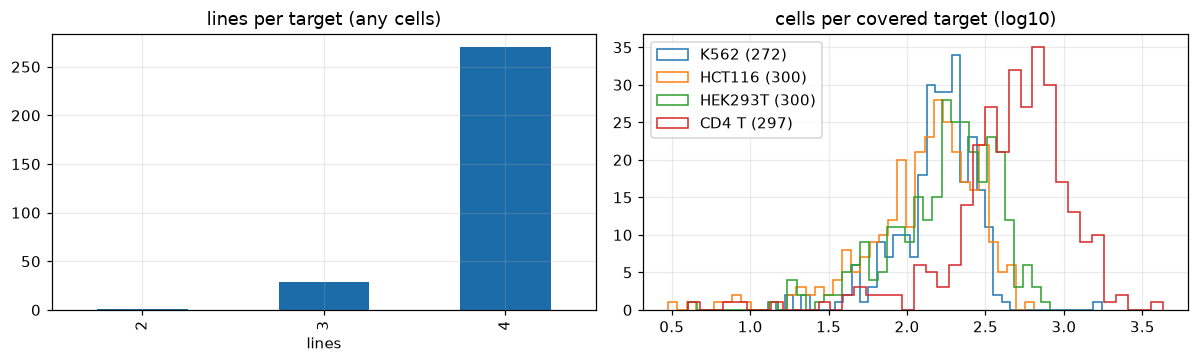

,K562,HCT116,HEK293T,CD4 T,n_lines
count,272.0,300.0,300.0,297.0,300.0
mean,181.0,165.0,221.0,613.0,4.0
std,123.0,107.0,141.0,457.0,0.0
min,13.0,3.0,4.0,4.0,2.0
25%,126.0,87.0,113.0,328.0,4.0
50%,168.0,149.0,200.0,521.0,4.0
75%,224.0,223.0,306.0,778.0,4.0
max,1745.0,648.0,819.0,4299.0,4.0


In [7]:
cov = pd.read_csv(C.OUT / "coverage_targets.csv", index_col=0)
lines = ["K562", "HCT116", "HEK293T", "CD4 T"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
cov["n_lines"].value_counts().sort_index().plot.bar(ax=ax[0], color="#1b6ca8"); ax[0].set(title="lines per target (any cells)", xlabel="lines")
for c in lines:
    v = cov[c].dropna(); ax[1].hist(np.log10(v), 40, histtype="step", label=f"{c} ({len(v)})")
ax[1].set(title="cells per covered target (log10)"); ax[1].legend(); plt.tight_layout(); plt.show()
cov[lines + ["n_lines"]].describe().round(0)

**Questions to try**
- Which targets have fewer than 50 cells in two or more lines? (they will have wide `s`)
- Is coverage related to the target's expression in the controls (section 1b)?
- Do the 28 targets missing from K562 differ in expression or function from the rest?

## 3. K562 genome-wide pseudobulk
What do effects look like in the largest cheap source? (`replogle/K562_gwps_raw_bulk_01.h5ad`)

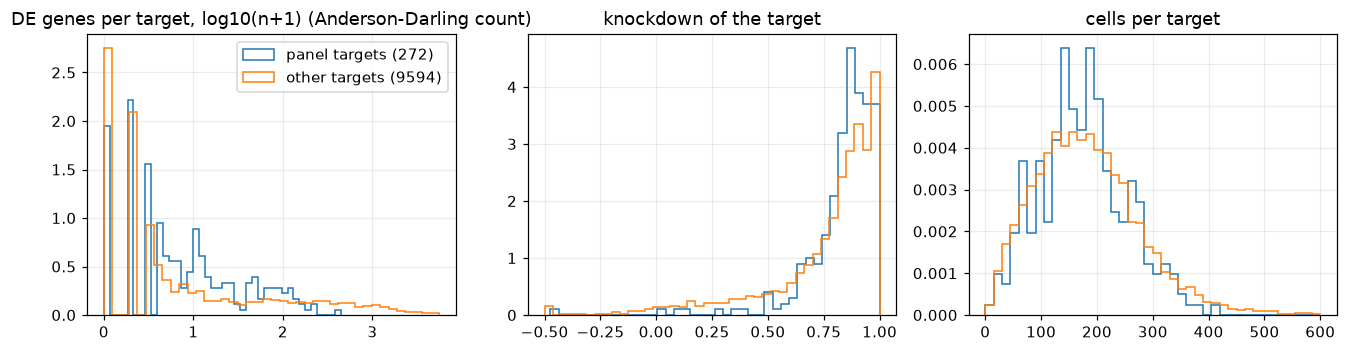

          n_de        kd  cells
in_panel                       
False      2.0  0.850961  173.0
True       5.0  0.870144  168.5


In [8]:
b = io.read_replogle_bulk(C.SOURCES / "replogle" / "K562_gwps_raw_bulk_01.h5ad")
meta, X, kg = b["meta"], b["X"], np.array(b["genes"])
tg = meta[~meta.is_nt].sort_values("cells", ascending=False).drop_duplicates("symbol").set_index("symbol")
tg["in_panel"] = tg.index.isin(panel)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for flag, lab in ((True, "panel targets"), (False, "other targets")):
    d = tg[tg.in_panel == flag]
    ax[0].hist(np.log10(d.n_de + 1), 40, histtype="step", density=True, label=f"{lab} ({len(d)})")
    ax[1].hist(d.kd.clip(-.5, 1.1), 40, histtype="step", density=True, label=lab)
    ax[2].hist(d.cells, 40, range=(0, 600), histtype="step", density=True, label=lab)
ax[0].set(title="DE genes per target, log10(n+1) (Anderson-Darling count)"); ax[1].set(title="knockdown of the target"); ax[2].set(title="cells per target")
ax[0].legend(); plt.tight_layout(); plt.show()
print(tg.groupby("in_panel")[["n_de", "kd", "cells"]].median())

In [9]:
# Noise from the 585 non-targeting pseudobulks: sd of beta * sqrt(cells) should be flat in cells (1/sqrt(n) scaling).
cpm = X / X.sum(1, keepdims=True) * 1e6
ok = meta.is_nt.to_numpy() & (meta.cells.to_numpy() >= 20)
w = meta.cells.to_numpy()[ok]
pool = (cpm[ok] * w[:, None]).sum(0) / w.sum()
beta_nt = np.log2((cpm[ok] + 1) / (pool + 1))
mid = (pool > 50) & (pool < 200)
bins = pd.qcut(w, 5)
sd = pd.DataFrame({"cells": w, "z": np.nanstd(beta_nt[:, mid], axis=1) * np.sqrt(w), "sd_beta": np.nanstd(beta_nt[:, mid], axis=1)})
print(sd.groupby(bins, observed=True).agg(cells=("cells", "median"), sd_beta=("sd_beta", "median"), sd_beta_x_sqrt_n=("z", "median")).round(3))

                cells  sd_beta  sd_beta_x_sqrt_n
(20.999, 82.6]   59.5    0.206             1.584
(82.6, 116.0]   104.0    0.155             1.569
(116.0, 156.0]  137.0    0.135             1.568
(156.0, 202.4]  173.0    0.119             1.567
(202.4, 561.0]  246.0    0.100             1.562


**Questions to try**
- Which genes have the largest `n_de` among panel targets? Do they share a function (check against `docs/` notes)?
- Plot `beta` for one strong target (e.g. SMARCA5) against pool CPM: is the spread wider at low expression, as `s` predicts?
- How many panel targets have `kd` below 0.5 (weak knockdown, will look like "no effect")?

## 4. K562 versus CD4+ T cells: do effects transfer?
Results of `04_concordance_k562_cd4.py`.

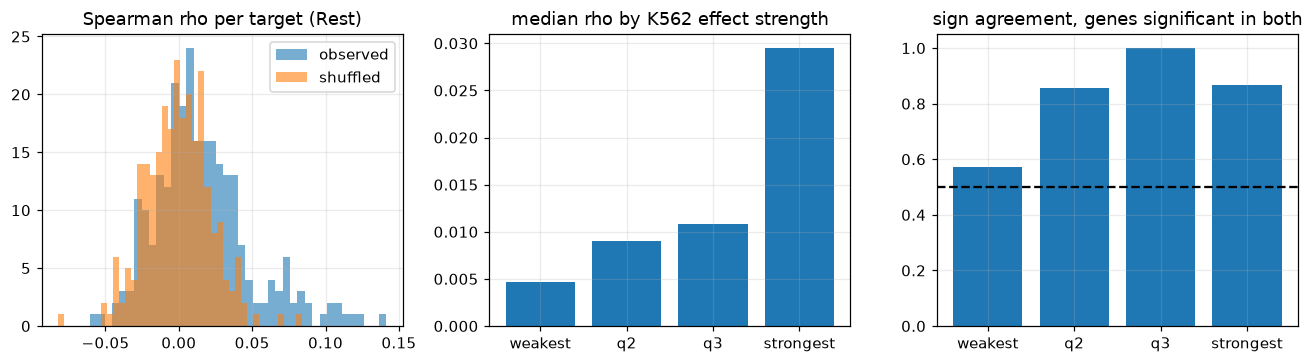

targets 259 | rho median 0.01 | rho > 0.1: 9


,target,k562_de,n_hits_cd4,n_hits_both,rho,sign_agree_both
35,DCP2,229,389,12,0.141,0.917
60,GIGYF2,71,148,11,0.124,1.000
93,MED13,84,97,3,0.120,NaN
168,SIN3B,74,569,14,0.114,0.857
47,E2F1,65,146,3,0.108,NaN
56,FOXN2,49,153,29,0.107,1.000
172,SMARCA5,138,1148,30,0.105,0.867
19,CARM1,74,123,7,0.102,1.000
138,PQBP1,103,89,10,0.101,0.900
150,R3HCC1L,2,167,3,0.090,NaN


In [10]:
res = pd.read_csv(C.OUT / "concordance_k562_cd4.csv")
r = res[res.condition == "Rest"].copy()
bm = tg.n_de.reindex(r.target).to_numpy()
r["k562_de"] = bm
r["k562_strength"] = pd.qcut(r.k562_de.rank(method="first"), 4, labels=["weakest", "q2", "q3", "strongest"])
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(r.rho, 40, alpha=.6, label="observed"); ax[0].hist(r.rho_null, 40, alpha=.6, label="shuffled"); ax[0].set(title="Spearman rho per target (Rest)"); ax[0].legend()
g = r.groupby("k562_strength", observed=True)
ax[1].bar(range(4), g.rho.median(), tick_label=g.rho.median().index); ax[1].set(title="median rho by K562 effect strength")
ax[2].bar(range(4), g.sign_agree_both.median(), tick_label=g.sign_agree_both.median().index); ax[2].axhline(.5, color="k", ls="--"); ax[2].set(title="sign agreement, genes significant in both")
plt.tight_layout(); plt.show()
print("targets", len(r), "| rho median", r.rho.median().round(3), "| rho > 0.1:", int((r.rho > .1).sum()))
r.sort_values("rho", ascending=False).head(10)[["target", "k562_de", "n_hits_cd4", "n_hits_both", "rho", "sign_agree_both"]].round(3)

**Read:** over all shared genes the agreement is near zero (median rho 0.01), but where both lines call a gene
significant the sign agrees in 86 to 100% of cases. The panel targets are mostly weak (K562 median 5 DE genes) and a
170-cell pseudobulk is noisy, so few genes are significant in both. This is the first estimate of how much a transfer
approach can buy, and how large `tau^2` must be handled.

**Questions to try**
- Repeat with a looser threshold (|z| > 2) and with the CD4+ T `Stim8hr` or `Stim48hr` rows.
- Does agreement depend on the response gene's expression level (use `pool` from section 3)?
- Take the strongest 30 targets and look at the scatter of `beta_K562` against CD4+ T log fold change.

## 5. Gene universe: which response genes matter?
Needs `01_context_summary.py` and `06_gene_coverage.py` (`eda/out/gene_lines.csv`).

**How the non-targeting cells are used**
- *In the organisers' contexts A, B, C* every cell is a non-targeting control. They are the only cells we have there: they give
  the baseline expression (mean CPM) of every gene in each context, and the scorer's 5 CPM filter is applied to exactly this mean.
  There is no perturbed cell in A, B, C; those are what we predict.
- *In each source line* the non-targeting cells are the control group of Stage 1: `beta_hat = log2(mean_perturbed / mean_control)`
  per (target, response gene). The spread of the non-targeting groups also gives `s` for pseudobulk sources (section 3) and the
  null calibration (section 1c).
- So "expression level" exists at two places: the **control CPM of every gene** (all lines, A/B/C included) and the **perturbed
  CPM per (target, gene)**, which only the source lines have.

**The filter.** The scorer tests a gene in a context only if its control mean exceeds 5 CPM *in that context*, so the set differs per
context. A gene matters for us if it passes in **at least one** context (we drop only genes that are at or below 5 CPM in all three).
D, E and F will have their own controls, so the A/B/C union is a proxy: a looser 1 CPM universe is shown next to it.

In [11]:
gl = pd.read_csv(C.OUT / "gene_lines.csv", index_col=0)
cp = gl[[f"cpm_{c}" for c in CTX]]
rows = []
for thr in (1, 5):
    above = cp > thr
    rows.append({"threshold CPM": thr, **{f"{c} passes": int(above[f"cpm_{c}"].sum()) for c in CTX},
                 "union (any context)": int(above.any(axis=1).sum()),
                 "intersection (all three)": int(above.all(axis=1).sum()),
                 "dropped (at or below in all three)": int((~above.any(axis=1)).sum())})
pd.DataFrame(rows).set_index("threshold CPM")

,A passes,B passes,C passes,union (any context),intersection (all three),dropped (at or below in all three)
threshold CPM,,,,,,
1,11199,11121,11654,13362,9405,5171
5,9929,9626,10124,11961,7991,6572


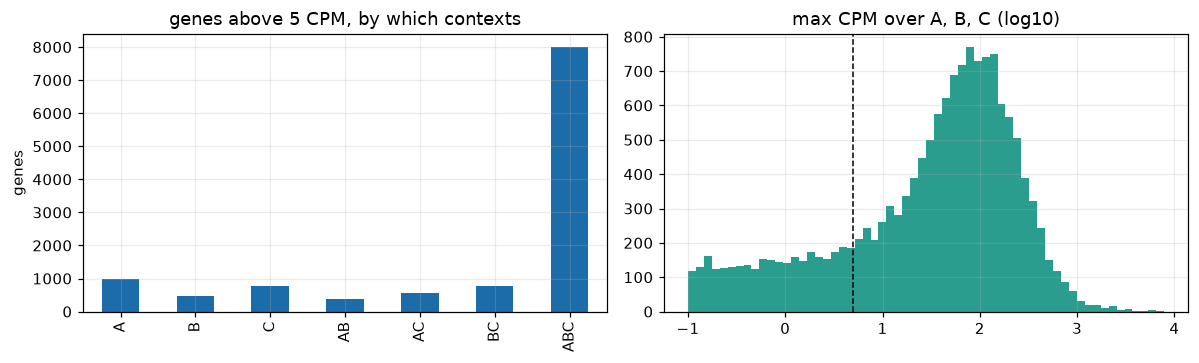

{'A': 989, 'B': 459, 'C': 786, 'AB': 389, 'AC': 560, 'BC': 787, 'ABC': 7991}


In [12]:
above = cp > C.CPM_FILTER
pat = above.apply(lambda r: "".join(c for c, v in zip(CTX, r) if v) or "none", axis=1)
vc = pat.value_counts().drop("none", errors="ignore").reindex(["A", "B", "C", "AB", "AC", "BC", "ABC"]).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
vc.plot.bar(ax=ax[0], color="#1b6ca8"); ax[0].set(title="genes above 5 CPM, by which contexts", ylabel="genes")
ax[1].hist(np.log10(gl.max_cpm[gl.max_cpm > 0.1]), 60, color="#2a9d8f")
ax[1].axvline(np.log10(C.CPM_FILTER), color="k", ls="--", lw=1); ax[1].set(title="max CPM over A, B, C (log10)")
plt.tight_layout(); plt.show()
print(vc.astype(int).to_dict())

**Questions to try**
- Which genes are above 5 CPM only in one context? Are they the context's marker genes (section 1)?
- How many genes sit between 1 and 5 CPM in all three? These matter only if D, E, F express them higher.

## 6. Which genes does each source line measure?
A gene is **present** in a line if it is detected there (K562: pooled control CPM at least 1; CD4+ T: on the DE-statistics axis).
HCT116, HEK293T and H1 are not downloaded yet: their code is commented out below and the result is given as a lower bound
(unknown = absent) and an upper bound (unknown = present).

In [13]:
BINS, NAMES = [5, 10, 50, 200, 1000, np.inf], ["5-10", "10-50", "50-200", "200-1000", ">1000"]
uni = gl[gl.max_cpm > C.CPM_FILTER].copy()
uni["bin"] = pd.cut(uni.max_cpm, BINS, labels=NAMES, right=False)
avail = {"K562": uni["in_K562"].astype(bool), "CD4 T": uni["in_CD4 T"].astype(bool)}
avail["H1 (benchmark)"] = uni["in_H1"].astype(bool)      # gene axis of the Arc H1 release; benchmark line, not counted in lines

# ---- uncomment when the files exist (docs/archive/EDA_PLAN.md, phases 3 and 5) -------------------------------------------
# for line in ("HCT116", "HEK293T"):            # eda/out/gene_cpm_<LINE>.csv: columns gene, mean_cpm (streaming pass)
#     d = pd.read_csv(C.OUT / f"gene_cpm_{line}.csv").drop_duplicates("gene").set_index("gene").mean_cpm
#     avail[line] = pd.Series(d.reindex(uni.index).fillna(0).to_numpy() >= 1, index=uni.index)
# -----------------------------------------------------------------------------------------------------------------

share = pd.DataFrame({k: v.groupby(uni["bin"], observed=True).mean() for k, v in avail.items()})
share.loc["all"] = [v.mean() for v in avail.values()]
print(f"universe: {len(uni)} genes above 5 CPM in at least one of A, B, C")
share.round(2)

universe: 11961 genes above 5 CPM in at least one of A, B, C


,K562,CD4 T,H1 (benchmark)
bin,,,
5-10,0.14,0.49,0.97
10-50,0.40,0.71,0.99
50-200,0.77,0.84,0.99
200-1000,0.84,0.87,0.99
>1000,0.67,0.71,0.99
all,0.63,0.78,0.99


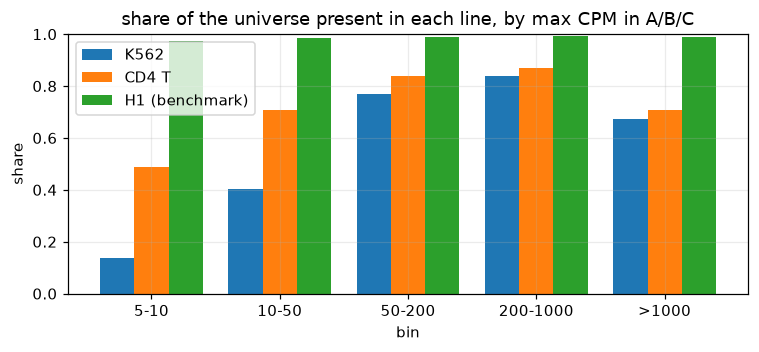

In [14]:
ax = share.drop("all").plot.bar(figsize=(7, 3.3), width=.8)
ax.set(title="share of the universe present in each line, by max CPM in A/B/C", ylabel="share", ylim=(0, 1)); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 7. Lines per (target, response gene) pair
A pair gets a `beta_hat` from a line only if the line measured the target (at least 50 cells) **and** detected the gene.
`pairs_ge3_lower` counts only the lines already in hand; `pairs_ge3_upper` assumes HCT116 and HEK293T detect everything.

In [15]:
ps = pd.read_csv(C.OUT / "pair_lines_summary.csv")
piv = ps.pivot(index="cpm_bin", columns="context", values="pairs_ge3_upper").reindex(NAMES + ["all testable"])
print("share of (target, gene) pairs that can reach 3 lines (upper bound); lower bound is 0 until a third line is read")
piv.round(2)

share of (target, gene) pairs that can reach 3 lines (upper bound); lower bound is 0 until a third line is read


context,A,B,C
cpm_bin,,,
5-10,0.62,0.68,0.63
10-50,0.79,0.77,0.77
50-200,0.87,0.84,0.84
200-1000,0.88,0.84,0.84
>1000,0.81,0.76,0.70
all testable,0.82,0.80,0.79


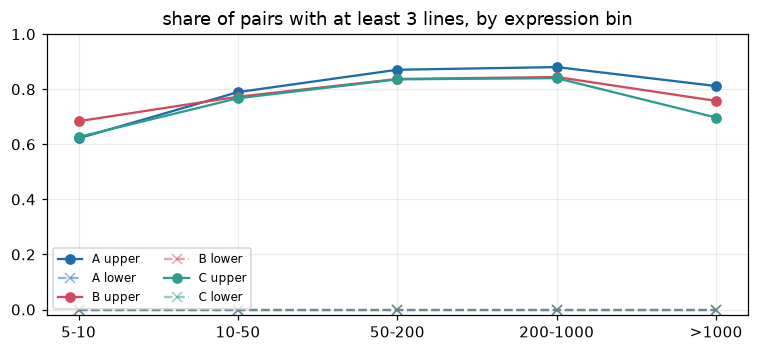

In [16]:
t2 = ps[ps.cpm_bin != "all testable"]
fig, ax = plt.subplots(figsize=(7, 3.3))
for c in CTX:
    s = t2[t2.context == c].set_index("cpm_bin").reindex(NAMES)
    ax.plot(NAMES, s.pairs_ge3_upper, "o-", color=colors[c], label=f"{c} upper")
    ax.plot(NAMES, s.pairs_ge3_lower, "x--", color=colors[c], alpha=.5, label=f"{c} lower")
ax.set(title="share of pairs with at least 3 lines, by expression bin", ylim=(-.02, 1)); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## 8. Under-represented genes
Genes above 5 CPM in at least one context that **cannot reach 3 lines even if HCT116 and HEK293T measured them**
(`gene_lines_upper < 3`): the lymphoid lines K562 and CD4+ T miss them, so a prediction must come from the prior or from gene features.

In [17]:
uni

,cpm_A,cpm_B,cpm_C,in_K562,in_HCT116,in_HEK293T,in_CD4 T,in_H1,gene_lines_lower,gene_lines_upper,testable_any,max_cpm,pair_median_lower,pair_ge3_share_lower,pair_ge3_share_upper,bin
gene,,,,,,,,,,,,,,,,
TSPAN6,0.008317,131.723190,146.163770,False,NaN,NaN,False,True,0,2,True,146.163770,0.0,0.0,0.000000,50-200
DPM1,202.895070,307.848300,479.151600,True,NaN,NaN,True,True,2,4,True,479.151600,2.0,0.0,0.910000,200-1000
SCYL3,19.501139,8.483151,16.446661,True,NaN,NaN,True,True,2,4,True,19.501139,2.0,0.0,0.910000,10-50
C1orf112,149.800140,52.622900,44.439410,True,NaN,NaN,True,True,2,4,True,149.800140,2.0,0.0,0.910000,50-200
FGR,5.350903,0.009361,0.743995,False,NaN,NaN,False,True,0,2,True,5.350903,0.0,0.0,0.000000,5-10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
DERPC,5.151316,0.451240,0.584749,False,NaN,NaN,False,True,0,2,True,5.151316,0.0,0.0,0.000000,5-10
NOTCH2NLC,66.570180,26.606936,23.479734,False,NaN,NaN,False,False,0,2,True,66.570180,0.0,0.0,0.000000,50-200
GABARAPL2,103.747270,83.869900,85.308890,True,NaN,NaN,False,False,1,3,True,103.747270,1.0,0.0,0.746667,50-200


In [18]:
under = uni[uni.gene_lines_upper < 3].copy()
under["top_ctx"] = under[[f"cpm_{c}" for c in CTX]].idxmax(axis=1).str.replace("cpm_", "")
print(f"{len(under)} of {len(uni)} genes ({len(under) / len(uni):.1%}) cannot reach 3 lines")
mass = []
for c in CTX:
    t = gl[gl[f"cpm_{c}"] > C.CPM_FILTER]
    u = t[t.gene_lines_upper < 3]
    mass.append({"context": c, "testable genes": len(t), "under-represented": len(u),
                 "share of genes": len(u) / len(t), "share of total CPM of testable genes": u[f"cpm_{c}"].sum() / t[f"cpm_{c}"].sum()})
display(pd.DataFrame(mass).set_index("context").round(3))
fam = under.index.str.extract(r"^([A-Z]+)", expand=False).value_counts().head(12)
print("most common gene-name prefixes among them:", fam.to_dict())
under.sort_values("max_cpm", ascending=False).head(25)[[f"cpm_{c}" for c in CTX] + ["top_ctx", "in_K562", "in_CD4 T"]].round(1)

1720 of 11961 genes (14.4%) cannot reach 3 lines


,testable genes,under-represented,share of genes,share of total CPM of testable genes
context,,,,
A,9929,636,0.064,0.025
B,9626,905,0.094,0.065
C,10124,1057,0.104,0.075


most common gene-name prefixes among them: {'C': 42, 'FAM': 29, 'ZNF': 27, 'SLC': 24, 'COL': 17, 'TMEM': 16, 'CCDC': 14, 'ARHGEF': 12, 'KRT': 12, 'KIAA': 10, 'MMP': 10, 'HIST': 10}


,cpm_A,cpm_B,cpm_C,top_ctx,in_K562,in_CD4 T
gene,,,,,,
TACSTD2,0.0,88.6,2762.8,C,False,False
MYO7B,2435.6,0.0,0.0,A,False,False
KRT7,0.0,2428.4,7.1,B,False,False
KRT15,0.0,2.5,2145.9,C,False,False
COL5A1,1.3,2141.8,3.1,B,False,False
FXYD3,0.0,0.3,1979.9,C,False,False
KRT5,0.0,0.0,1812.2,C,False,False
TGFBI,0.0,1797.2,333.1,B,False,False
MAL2,0.0,70.8,1721.7,C,False,False


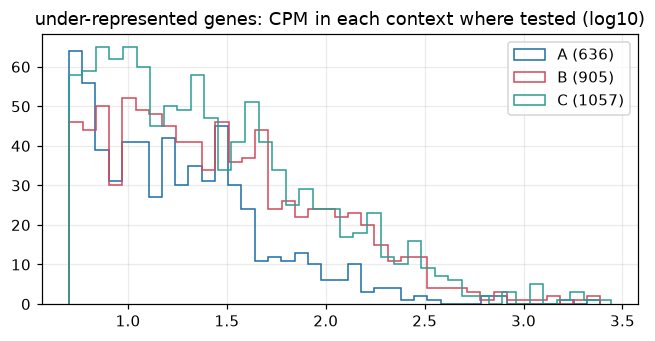

In [19]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for c in CTX:
    v = under[f"cpm_{c}"]; v = v[v > C.CPM_FILTER]
    ax.hist(np.log10(v), 40, histtype="step", color=colors[c], label=f"{c} ({len(v)})")
ax.set(title="under-represented genes: CPM in each context where tested (log10)"); ax.legend()
plt.tight_layout(); plt.show()

**Questions to try**
- Are the under-represented genes concentrated in one context (the share of total CPM above answers how much it could cost)?
- Which families dominate (keratins, S100, collagens)? Do they form a module whose knockdown response could be predicted as a block?
- Re-run `06_gene_coverage.py --min-cpm 5` and `--min-cells 100`: how much does the list grow?

**Decision after HCT116 and HEK293T are streamed:** genes still below 3 lines go to the sparse prior with a wide `sd`
(`beta = 0`), unless a gene-feature rung (v5 to v7) beats that on H1.

## 9. Later: the stacked Stage 1 table (all commented until the data are on disk)
The common per-line format is `(line, target, gene) -> beta_hat, s, n_cells` over the 5 CPM universe of section 5.
Pseudobulk sources get it from group means; CD4+ T keeps its DESeq2 `log_fc` and `lfcSE`; H1 is built the same way and stays the benchmark.

In [20]:
# ---- uncomment after docs/archive/EDA_PLAN.md phases 3 to 5 -----------------------------------------------------------------
# universe = list(uni.index)                                   # genes above 5 CPM in A, B or C
# tables = {}
# for line in ("K562", "CD4 T", "HCT116", "HEK293T"):          # H1 separately, as the held-out line
#     tables[line] = np.load(C.OUT / f"stage1_{line.replace(' ', '_')}.npz", allow_pickle=True)   # beta, s, n, targets, genes
# # pair-level count of finite, positive-variance estimates
# stack_beta = np.stack([t["beta"] for t in tables.values()])   # lines x targets x genes (align targets, genes first)
# stack_s = np.stack([t["s"] for t in tables.values()])
# n_lines = (np.isfinite(stack_beta) & (stack_s > 0)).sum(axis=0)
# print("pairs with >= 3 lines:", float((n_lines >= 3).mean()))
# ------------------------------------------------------------------------------------------------------------------
print("section 9 is a placeholder until the Stage 1 tables exist")

section 9 is a placeholder until the Stage 1 tables exist


## 10. H1 benchmark data (Arc, train + validation + test)
Downloaded with `05_download_h1.py` to `data/sources/h1/`. What the files contain (checked on 2026-10-14):
- Three h5ad files, each with its own perturbed cells **plus the same 38,176 non-targeting cells** (identical barcodes in all three).
  Combine the splits by taking the perturbed cells of each and the controls once: 376,518 perturbed + 38,176 control cells.
- `X` is a CSR matrix of raw counts (float32, integer values), 18,080 genes (`gene_names.csv` has no header row).
- `obs` has `target_gene` (`non-targeting` for controls), `guide_id` (dual guide `A|B`; designs P1P2, P1, P2) and `batch`
  (48 10x Flex batches; controls are 16 to 18% of every batch, so matched-batch controls are possible).
- Depth is about 54,000 UMI per cell (median per target), more than twice the 20,000 of A, B, C: compare in CPM and expect less
  noise per cell than in the contest data.

In [21]:
H1 = C.SOURCES / "h1"
splits = {"train": "Training", "validation": "Validation", "test": "Test"}
pc = pd.concat([pd.read_csv(H1 / d / f"pert_counts_{s}.csv").assign(split=d) for d, s in splits.items()], ignore_index=True)
pc["in_panel"] = pc.target_gene.isin(panel)
pc.groupby("split").agg(targets=("target_gene", "size"), cells=("n_cells", "sum"), median_cells=("n_cells", "median"),
                        min_cells=("n_cells", "min"), median_umi=("median_umi_per_cell", "median"), in_2026_panel=("in_panel", "sum"))

,targets,cells,median_cells,min_cells,median_umi,in_2026_panel
split,,,,,,
test,100,132670,1141.5,67,54285.00,8
train,150,183097,1045.0,33,53994.50,13
validation,50,60751,1090.5,161,54446.75,4


In [22]:
pc.head()

,target_gene,n_cells,median_umi_per_cell,split,in_panel
0,TMSB4X,4760,53652.0,train,False
1,PRCP,4331,54594.0,train,False
2,TADA1,4035,52376.0,train,False
3,HIRA,3407,54068.0,train,False
4,IGF2R,3109,55754.0,train,False


In [23]:
# overlap with the source lines (K562 and CD4+ T from sections 2 to 4; X-Atlas guide calls from data/sources/xatlas)
sets = {"K562": set(tg.index)}
for line in ("HCT116", "HEK293T"):
    g = pd.read_csv(C.SOURCES / "xatlas" / f"{line}_filtered_guide_calls_per_cell.csv.gz", usecols=["gene_target", "pass_guide_filter"])
    sets[line] = set(g[g.pass_guide_filter.astype(str).str.lower() == "true"].gene_target)
z = pd.read_csv(C.SOURCES / "zhu" / "guide_kd_efficiency.suppl_table.csv", index_col=0)
sets["CD4 T"] = set(z.index.str.replace(r"-\d+$", "", regex=True))
for k, s in sets.items():
    pc[f"in_{k}"] = pc.target_gene.isin(s)
pc["n_lines"] = pc[[f"in_{k}" for k in sets]].sum(axis=1)
tab = pc.groupby("split")[[f"in_{k}" for k in sets]].sum().assign(targets=pc.groupby("split").size())
print("H1 targets in at least 3 of the 4 source lines:", int((pc.n_lines >= 3).sum()), "of", len(pc), "| in all 4:", int((pc.n_lines == 4).sum()))
tab

H1 targets in at least 3 of the 4 source lines: 293 of 300 | in all 4: 271


,in_K562,in_HCT116,in_HEK293T,in_CD4 T,targets
split,,,,,
test,97,100,100,98,100
train,136,149,149,143,150
validation,47,50,50,45,50


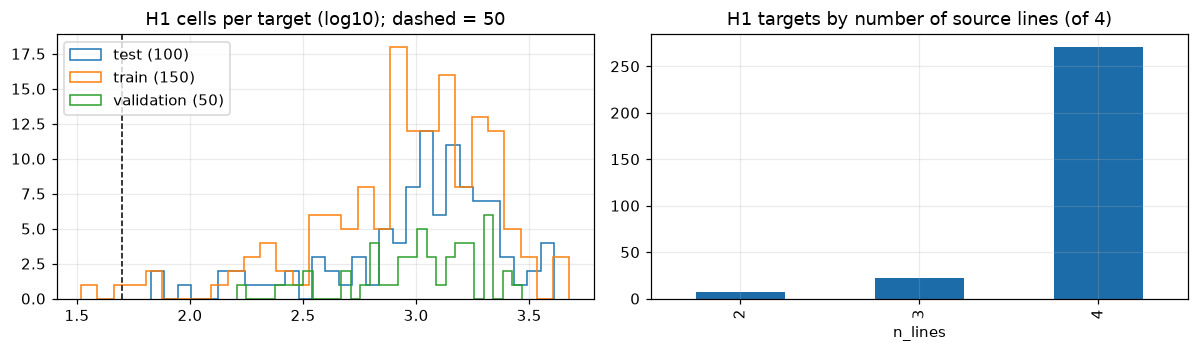

targets with fewer than 50 cells: [['RNF20', 'train', 47], ['ATP6V0C', 'train', 33]]


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for s, d in pc.groupby("split"):
    ax[0].hist(np.log10(d.n_cells), 30, histtype="step", label=f"{s} ({len(d)})")
ax[0].axvline(np.log10(50), color="k", ls="--", lw=1); ax[0].set(title="H1 cells per target (log10); dashed = 50"); ax[0].legend()
pc.n_lines.value_counts().sort_index().plot.bar(ax=ax[1], color="#1b6ca8"); ax[1].set(title="H1 targets by number of source lines (of 4)")
plt.tight_layout(); plt.show()
print("targets with fewer than 50 cells:", pc[pc.n_cells < 50][["target_gene", "split", "n_cells"]].values.tolist())

In [25]:
import h5py
with h5py.File(H1 / "train" / "adata_Training.h5ad", "r") as f:           # obs only: a few seconds, no counts read
    obs1 = io.read_df_group(f["obs"])
    n_cells_f, n_genes_f = (int(v) for v in f["X"].attrs["shape"])
is_nt = obs1.target_gene == "non-targeting"
print(f"train file: {n_cells_f} cells x {n_genes_f} genes; {int(is_nt.sum())} non-targeting; {obs1.batch.nunique()} batches")
print("non-targeting guide pairs:", obs1.guide_id[is_nt].nunique(), "| guide designs among perturbed:",
      obs1.guide_id[~is_nt].str.extract(r"_(P\d+(?:P\d+)?)_A")[0].value_counts().to_dict())
(obs1.assign(nt=is_nt).groupby("batch").nt.agg(["size", "mean"]).describe().round(3))

train file: 221273 cells x 18080 genes; 38176 non-targeting; 48 batches


non-targeting guide pairs:

 31 | guide designs among perturbed: {'P1P2': 160687, 'P1': 11157, 'P2': 8430}


,size,mean
count,48.000,48.000
mean,4609.854,0.173
std,256.866,0.006
min,4083.000,0.157
25%,4432.250,0.169
50%,4556.500,0.172
75%,4828.000,0.176
max,5082.000,0.184


**Questions to try**
- Do the 25 targets shared with the 2026 panel have the same effect sizes in H1 as in K562 (section 4 logic)?
- Do the controls of different Flex batches differ (batch effects)? If so, Stage 1 for H1 should use matched-batch controls.
- Which of the 7 targets below 3 lines are they, and how many cells do they have?

### 10b. Later: H1 counts as a Stage 1 source for the benchmark (commented until the loader exists)

In [26]:
# ---- reading counts: 1.9e9 non-zeros in the train file alone; stream by row block, never load whole ---------------
# for split, fname in (("train", "adata_Training.h5ad"), ("validation", "adata_Validation.h5ad"), ("test", "adata_Test.h5ad")):
#     with h5py.File(H1 / split / fname, "r") as f:
#         indptr = f["X"]["indptr"][...]
#         for start in range(0, n_cells_f, 50_000):                  # accumulate per-target sums on the 5 CPM universe
#             ...                                                     # see docs/archive/EDA_PLAN.md phase 3
# controls are identical in the three files: use them from the train file only
print("section 10b is a placeholder until the H1 Stage 1 builder (eda/07_stage1_table.py) exists")

section 10b is a placeholder until the H1 Stage 1 builder (eda/07_stage1_table.py) exists


## 11. Pooling test with four lines: why `z_sd` was 8.8 for HCT116 (and what it was not)

**What we saw.** `09_eval_stage2.py` reports `z_sd`, the spread of (truth - prediction) / sqrt(predictive sd^2 + s_truth^2). If the stated uncertainty is honest it is about 1. For HCT116 it came out at 8.8 and for HEK293T at 2.4, with a skill of -90. My first guess was that the standard errors `s` of the X-Atlas lines were too small.

**Check 1 - is `s` honest?** If `s` is right, then `z = beta / s` over all (target, gene) pairs is mostly noise around zero, so the bulk of it should look like N(0, 1). The figure below tests that directly on each Stage 1 table. It does: the robust sd (MAD) of z is 1.04 to 1.09 for all four lines. `s` is **not** too small, so the guess was wrong.

**Check 2 - where do the huge z come from?** From rung v1 (the per-gene mean over all targets and lines). In HCT116 some genes are silent (control CPM about 0.0003) and flicker on in exactly one target out of 575. That one estimate (for example MYCN, beta = +9.1) is the only finite one, so the "mean over targets" is that single value and the "spread over targets" is exactly 0. v1 then predicts +9 log2 for every target with predictive sd 0, and in H1, where the gene is expressed, the error divided by sd explodes (z up to 1,000). The fallback of v2 to v3b onto v1 spreads it further. The problem is a missing minimum count in `generic()`, not the size of `s`.

**Fix** (`stage2.generic`): a gene needs at least 30 estimates before its own mean and spread are used; otherwise effect 0 and the typical spread of the other genes, plus a floor of 0.05 on the spread. The third figure shows `z_sd` before and after. Rank correlation and sign accuracy barely move, so the earlier pooling conclusions stand; what changes is the honesty of the stated uncertainty (and the skill score, which was dominated by those few genes).

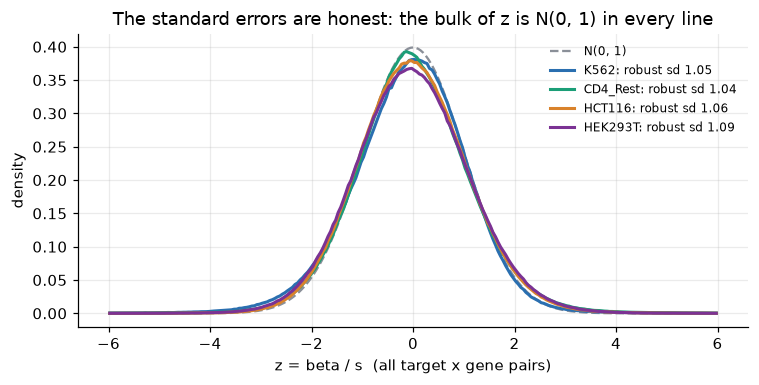

In [27]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vcell import config as C, io   # was eda/common.py

BLUE, ORANGE, GREY = "#2a6fb0", "#d9822b", "#8a8f98"
LINES = ["K562", "CD4_Rest", "HCT116", "HEK293T"]
tabs = {n: np.load(C.OUT / f"stage1_{n}.npz", allow_pickle=True) for n in LINES}

# Figure A: is s honest?  z = beta / s over all finite pairs; N(0,1) dashed
fig, ax = plt.subplots(figsize=(7, 3.6))
xs = np.linspace(-6, 6, 241)
ax.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), "--", color=GREY, lw=1.5, label="N(0, 1)")
cols = {"K562": BLUE, "CD4_Rest": "#1b9e77", "HCT116": ORANGE, "HEK293T": "#7b3294"}
for n in LINES:
    b, s = tabs[n]["beta"].astype(float), tabs[n]["s"].astype(float)
    ok = np.isfinite(b) & np.isfinite(s) & (s > 0)
    z = (b / s)[ok]
    mad = 1.4826 * np.median(np.abs(z - np.median(z)))
    h, e = np.histogram(z, bins=xs, density=True)
    ax.plot((e[1:] + e[:-1]) / 2, h, color=cols[n], lw=2, label=f"{n}: robust sd {mad:.2f}")
ax.set_xlabel("z = beta / s  (all target x gene pairs)"); ax.set_ylabel("density")
ax.set_title("The standard errors are honest: the bulk of z is N(0, 1) in every line")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

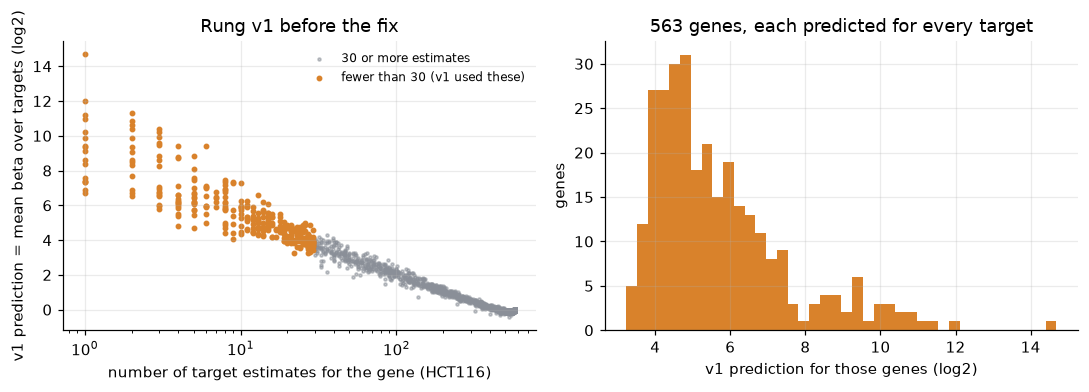

HCT116: 563 of 11961 genes have fewer than 30 estimates; 298 of them have a v1 prediction beyond +-2 log2


In [28]:
# Figure B: the real culprit - genes seen in very few estimates get a "mean" that is one noisy value
b = tabs["HCT116"]["beta"].astype(float)
nobs = np.isfinite(b).sum(0)
mean = np.nanmean(b, axis=0)
low = nobs < 30
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(nobs[~low], mean[~low], s=4, color=GREY, alpha=.5, label="30 or more estimates")
ax[0].scatter(nobs[low], mean[low], s=8, color=ORANGE, label="fewer than 30 (v1 used these)")
ax[0].set_xscale("log"); ax[0].set_xlabel("number of target estimates for the gene (HCT116)")
ax[0].set_ylabel("v1 prediction = mean beta over targets (log2)")
ax[0].set_title("Rung v1 before the fix"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(mean[low][np.isfinite(mean[low])], bins=40, color=ORANGE)
ax[1].set_xlabel("v1 prediction for those genes (log2)"); ax[1].set_ylabel("genes")
ax[1].set_title(f"{int(low.sum())} genes, each predicted for every target")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(f"HCT116: {int(low.sum())} of {len(low)} genes have fewer than 30 estimates; "
      f"{int((np.abs(mean[low]) > 2).sum())} of them have a v1 prediction beyond +-2 log2")

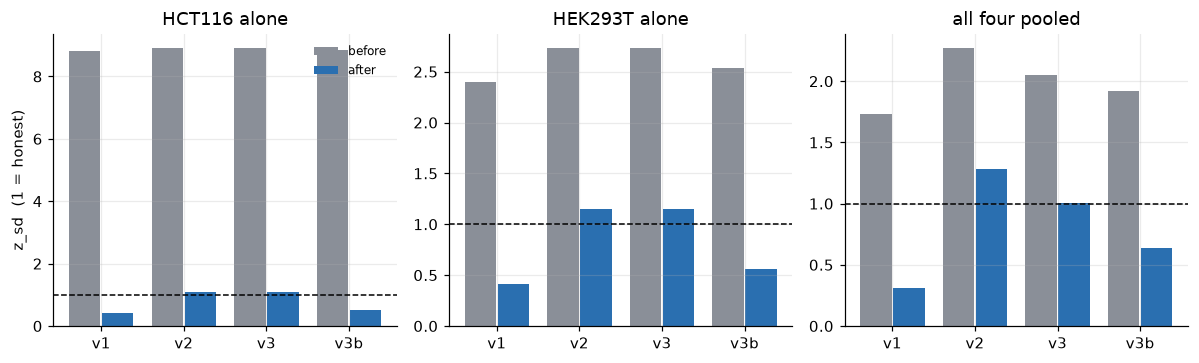

       before                                     after                                 
     spearman sign_acc prec_at_k   z_sd  skill spearman sign_acc prec_at_k   z_sd  skill
rung                                                                                    
v1      0.020    0.509     0.153  1.729 -2.987    0.020    0.508     0.153  0.307 -1.635
v2      0.036    0.551     0.144  2.271 -7.388    0.036    0.551     0.143  1.285 -5.931
v3      0.036    0.551     0.139  2.054 -7.397    0.036    0.551     0.139  1.005 -5.936
v3b     0.036    0.551     0.135  1.916 -2.427    0.036    0.551     0.134  0.636 -1.022
zero      NaN      NaN     0.128  0.080  0.000      NaN      NaN     0.128  0.080  0.000


In [29]:
# Figure C: z_sd before and after the fix (median over the 126 H1 benchmark targets; 1 = honest)
old = pd.read_csv(C.OUT / "stage2_eval_summary_4src.csv"); new = pd.read_csv(C.OUT / "stage2_eval_summary_4src_fix.csv")
pooled = "K562+CD4_Rest+HCT116+HEK293T"
rungs = ["v1", "v2", "v3", "v3b"]
rows = [("HCT116 alone", "HCT116"), ("HEK293T alone", "HEK293T"), ("all four pooled", pooled)]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.4), sharey=False)
for a, (title, key) in zip(axs, rows):
    o = old[old.lines == key].set_index("rung").z_sd.reindex(rungs)
    n_ = new[new.lines == key].set_index("rung").z_sd.reindex(rungs)
    x = np.arange(len(rungs))
    a.bar(x - .2, o, .38, color=GREY, label="before"); a.bar(x + .2, n_, .38, color=BLUE, label="after")
    a.axhline(1, color="k", lw=1, ls="--"); a.set_xticks(x); a.set_xticklabels(rungs)
    a.set_title(title); a.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("z_sd  (1 = honest)"); axs[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
cols = ["spearman", "sign_acc", "prec_at_k", "z_sd", "skill"]
print(pd.concat({"before": old[old.lines == pooled].set_index("rung")[cols],
                 "after": new[new.lines == pooled].set_index("rung")[cols]}, axis=1).round(3).to_string())

**How to read the result.**
- Figure A: `s` is calibrated on the source side. No per-line rescaling of `s` is needed at this point (this closes the "calibrate `s` per line" item, at least for the bulk; the tail share |z| > 3 is 0.9 to 1.5 per cent per line, about what a few real effects give).
- Figure B: the damage came from a few hundred genes that are essentially silent in the source line. They need a minimum-count rule in any "mean over targets" step; the same rule is worth applying to anything that averages over targets.
- Figure C: after the fix v1 is conservative (z_sd about 0.3 to 0.4, because the spread over all targets is wider than the spread around the truth), v2 and v3 are close to honest (1.0 to 1.3), and v3b (sparse prior) is conservative (0.5 to 0.6).
- Pooling itself: with four lines the best rung (v3b) reaches rank correlation 0.0365 and sign accuracy 0.551 against 0.0196 and 0.509 for v1, and 0.030 and 0.540 with K562 + CD4 only. Small, but each extra line helps. The absolute level is still close to chance, which is the main thing to keep in mind.

### 11b. The same metrics, scoring only genes that are expressed in the source lines too
`12_eval_by_cpm.py` reuses the same predictions (nothing is refitted) but lets the metrics see only genes whose control CPM is above a threshold in every source line that reports one (K562, HCT116, HEK293T; the CD4 tables carry no control CPM), on top of the 5 CPM filter in H1. Silent and lowly expressed genes are the noisiest ones, so this shows how much of the weak signal is simply noise at the low end.

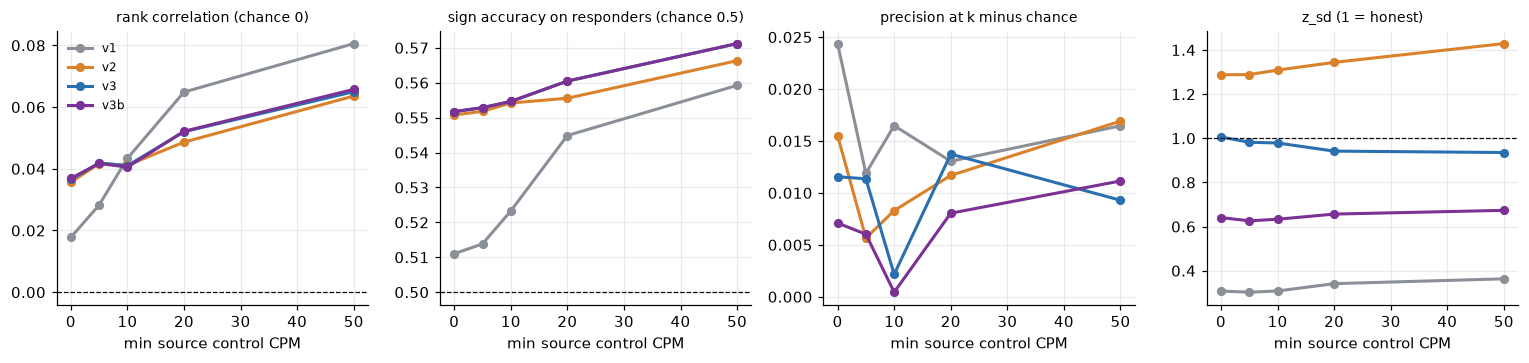

min_src_cpm                           0       5       10      20      50
genes scored (median per target)  9732.0  8364.0  7227.0  4777.0  2010.0


In [30]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from vcell import config as C, io   # was eda/common.py
r = pd.read_csv(C.OUT / "stage2_eval_by_cpm.csv")
col = {"v1": "#8a8f98", "v2": "#d9822b", "v3": "#2a6fb0", "v3b": "#7b3294"}
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for k, (m, title) in enumerate([("spearman", "rank correlation (chance 0)"), ("sign_acc", "sign accuracy on responders (chance 0.5)"),
                                ("lift", "precision at k minus chance"), ("z_sd", "z_sd (1 = honest)")]):
    for rung, d in r.groupby("rung"):
        y = d.prec_at_k - d.chance_prec if m == "lift" else d[m]
        ax[k].plot(d.min_src_cpm, y, "o-", color=col[rung], lw=2, ms=5, label=rung)
    ax[k].set_title(title, fontsize=9); ax[k].set_xlabel("min source control CPM")
    ax[k].spines[["top", "right"]].set_visible(False)
ax[1].axhline(.5, color="k", lw=.8, ls="--"); ax[0].axhline(0, color="k", lw=.8, ls="--"); ax[3].axhline(1, color="k", lw=.8, ls="--")
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
print(r.groupby("min_src_cpm").n_genes.first().rename("genes scored (median per target)").to_frame().T.to_string())

**Reading it.** Dropping genes that are low in the source lines raises every score, including the no-pooling baseline v1.
- Rank correlation: v1 catches up with the pooled rungs at about 10 CPM and passes them above that (0.08 vs 0.065 at 50 CPM), so for ranking, pooling adds nothing at high expression. Its gain over all genes comes from low and middle expression, where noise is largest.
- Sign accuracy: the pooled rungs stay ahead of v1 at every threshold (0.571 vs 0.559 at 50 CPM), so pooling still adds target-specific direction information.
- Precision at k minus chance is small (0.00 to 0.025) and jumps around between thresholds, so it carries no clear message.
- z_sd barely changes with the threshold, which confirms that the earlier overconfidence came from silent genes in v1 only.
This is a proxy on 126 H1 targets, not the contest score.

### 11c. Leaving low-expressed genes out of training
`13_train_mask.py` sets source estimates to missing for genes whose control CPM in that source line is at or below a threshold (0, 1, 5, 10, 20), refits every rung, and scores the same fixed gene sets: all genes above 5 CPM in H1, and the 'high' subset (above 20 CPM in every reporting source).

In [31]:
import pandas as pd
from vcell import config as C, io
t = pd.read_csv(C.OUT / "stage2_train_mask.csv")
for ev, d in t.groupby("eval_set"):
    print(f"scored on '{ev}' genes")
    print(d.pivot(index="train_min_cpm", columns="rung", values=["spearman", "sign_acc"]).round(3).to_string())
    print()

scored on 'all' genes
              spearman                      sign_acc                     
rung                v1     v2     v3    v3b       v1     v2     v3    v3b
train_min_cpm                                                            
0                0.020  0.036  0.036  0.037    0.508  0.551  0.551  0.551
1                0.023  0.036  0.037  0.037    0.508  0.552  0.551  0.551
5                0.024  0.038  0.038  0.038    0.506  0.550  0.549  0.549
10               0.031  0.036  0.036  0.036    0.511  0.553  0.552  0.552
20               0.038  0.034  0.035  0.032    0.523  0.553  0.552  0.552

scored on 'high' genes
              spearman                     sign_acc                    
rung                v1     v2     v3   v3b       v1    v2     v3    v3b
train_min_cpm                                                          
0                0.071  0.048  0.050  0.05    0.557  0.56  0.565  0.565
1                0.071  0.048  0.050  0.05    0.557  0.56  0.565  0.565
5 

**Result: no real gain.** On the 'high' genes the scores do not change at all (they were never masked). On all genes the pooled rungs move by at most 0.002 in rank correlation and 0.003 in sign accuracy; only v1 creeps up (0.020 to 0.038) when low genes are removed, and it stays below the pooled rungs. After the minimum-count fix in `generic()` the silent genes are no longer doing harm, so excluding them from training buys nothing and loses up to 44 per cent of the estimates. Keep all genes in training; use the CPM threshold only when reporting metrics.